# JC 主线：特征与经典基线
本 Notebook 只使用 2024 年开发数据进行滚动验证；2025 年最终测试集不在这里读取、评估或调参。
模型：上一小时/上一周朴素基准、线性回归、随机森林；另比较历史天气特征的开发折消融。

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.jc_baseline_models import load_prepared, load_weathered_prepared, run_development_cv
config = json.loads((ROOT / 'configs/jc_experiment.json').read_text(encoding='utf-8'))
frame = load_prepared()
print('prepared rows:', len(frame), 'development end:', config['final_fit_end_utc'])
assert pd.Timestamp(config['test_start_utc']) == pd.Timestamp('2025-01-01T05:00:00Z')
print('Final test is not loaded for model fitting in this notebook.')

prepared rows: 17544 development end: 2025-01-01T05:00:00Z
Final test is not loaded for model fitting in this notebook.


## 开发折验证
每个折只用训练区间拟合模型；验证区间使用当时可获得的历史滞后特征。这里的指标用于选择后续 MLP/LSTM 的输入方案，不是最终测试结果。

In [2]:
results, predictions = run_development_cv(frame, config, include_weather=False)
rows = []
for fold, values in results.items():
    for model, metrics in values.items():
        if isinstance(metrics, dict) and 'MAE' in metrics:
            rows.append({'feature_set': 'calendar+demand_history', 'fold': fold, 'model': model, **metrics})
baseline_table = pd.DataFrame(rows)
display(baseline_table)

,feature_set,fold,model,n,MAE,RMSE,R2
0,calendar+demand_history,fold_1,linear_regression,2208,26.887436,40.328345,0.881175
1,calendar+demand_history,fold_1,random_forest,2208,20.279441,32.483647,0.922907
2,calendar+demand_history,fold_1,naive_previous_hour,2208,45.820199,65.689415,0.684735
3,calendar+demand_history,fold_1,naive_previous_week,2208,32.034873,53.337620,0.792149
4,calendar+demand_history,fold_2,linear_regression,2039,22.111679,32.699586,0.903536
5,calendar+demand_history,fold_2,random_forest,2039,15.112219,23.465594,0.950324
6,calendar+demand_history,fold_2,naive_previous_hour,2039,35.771457,55.581592,0.721295
7,calendar+demand_history,fold_2,naive_previous_week,2039,30.390878,49.466725,0.779246


In [3]:
weathered = load_weathered_prepared()
weather_results, weather_predictions = run_development_cv(weathered, config, include_weather=True)
rows = []
for fold, values in weather_results.items():
    for model, metrics in values.items():
        if isinstance(metrics, dict) and 'MAE' in metrics:
            rows.append({'feature_set': 'calendar+demand+historical_weather', 'fold': fold, 'model': model, **metrics})
weather_table = pd.DataFrame(rows)
display(weather_table)

,feature_set,fold,model,n,MAE,RMSE,R2
0,calendar+demand+historical_weather,fold_1,linear_regression,2208,29.342594,40.740267,0.878736
1,calendar+demand+historical_weather,fold_1,random_forest,2208,20.962048,33.353755,0.918722
2,calendar+demand+historical_weather,fold_1,naive_previous_hour,2208,45.820199,65.689415,0.684735
3,calendar+demand+historical_weather,fold_1,naive_previous_week,2208,32.034873,53.337620,0.792149
4,calendar+demand+historical_weather,fold_2,linear_regression,2039,22.062947,31.565979,0.910108
5,calendar+demand+historical_weather,fold_2,random_forest,2039,15.698357,23.918600,0.948388
6,calendar+demand+historical_weather,fold_2,naive_previous_hour,2039,35.771457,55.581592,0.721295
7,calendar+demand+historical_weather,fold_2,naive_previous_week,2039,30.390878,49.466725,0.779246


## 结果解释
初始实验只用于开发折比较。随机森林目前优于线性回归和两个朴素基准，但历史天气加入后并非每个折都改善，因此不能预设天气特征一定带来增益。下一阶段将冻结输入方案后实现 MLP 与 LSTM。

C:\Users\nahida\AppData\Local\Temp\ipykernel_35408\2830165806.py:5: UserWarning: Glyph 24320 (\N{CJK UNIFIED IDEOGRAPH-5F00}) missing from current font.
  ax.set_title('开发折 MAE（不含 2025 最终测试）'); ax.set_ylabel('MAE'); fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_35408\2830165806.py:5: UserWarning: Glyph 21457 (\N{CJK UNIFIED IDEOGRAPH-53D1}) missing from current font.
  ax.set_title('开发折 MAE（不含 2025 最终测试）'); ax.set_ylabel('MAE'); fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_35408\2830165806.py:5: UserWarning: Glyph 25240 (\N{CJK UNIFIED IDEOGRAPH-6298}) missing from current font.
  ax.set_title('开发折 MAE（不含 2025 最终测试）'); ax.set_ylabel('MAE'); fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_35408\2830165806.py:5: UserWarning: Glyph 65288 (\N{FULLWIDTH LEFT PARENTHESIS}) missing from current font.
  ax.set_title('开发折 MAE（不含 2025 最终测试）'); ax.set_ylabel('MAE'); fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_35408\283016580

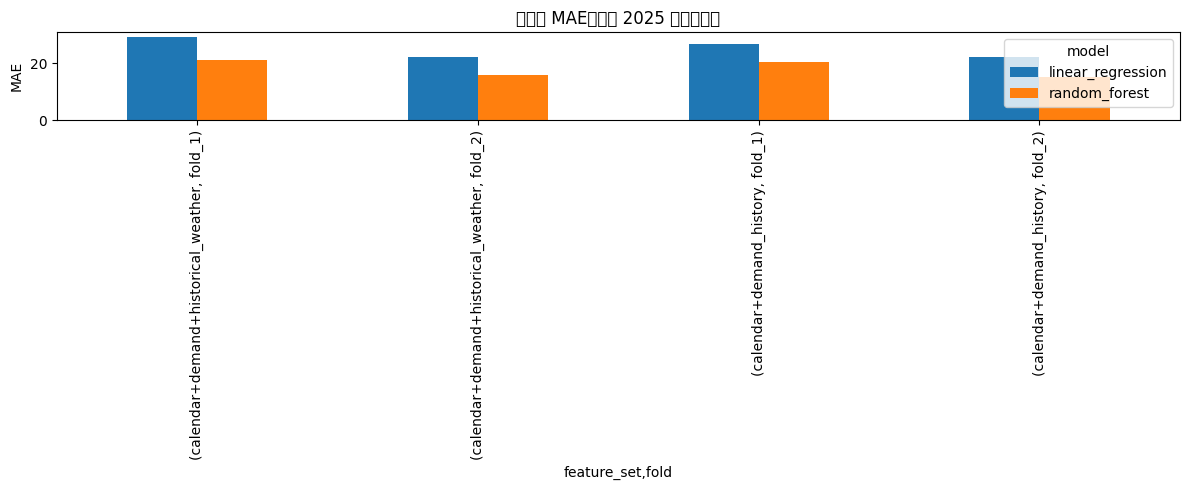

In [4]:
summary = pd.concat([baseline_table, weather_table], ignore_index=True)
summary.to_csv(ROOT / 'results/metrics/jc_baseline_development.csv', index=False)
fig, ax = plt.subplots(figsize=(12, 5))
summary[summary['model'].isin(['linear_regression','random_forest'])].pivot_table(index=['feature_set','fold'], columns='model', values='MAE').plot.bar(ax=ax)
ax.set_title('开发折 MAE（不含 2025 最终测试）'); ax.set_ylabel('MAE'); fig.tight_layout()
fig.savefig(ROOT / 'results/figures/jc_baseline_development.png', dpi=150, bbox_inches='tight')
plt.show()